We will now analyze the actual data

In [79]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from anndata.io import read_elem


peek at the structure of the .h5ad file (obs, var, layers) without loading the 1.19M x 33.5k count matrix, which is too big for memory.

In [80]:
with h5py.File(r"..\data\Full_cohort.h5ad", "r") as f:
    print('X type:', type(f['X']))  # Print the type of the 'X' dataset
    print(list(f.keys()))  # List the top-level groups in the HDF5 file
    print('obs keys:', list(f['obs'].keys()))  # List the keys in the 'obs' group
    print('var keys:', list(f['var'].keys()))  # List the keys in the 'var' group
    print('uns keys:', list(f['uns'].keys()))  # List the keys in the 'uns' group
    print('layers keys:', list(f['layers'].keys()))  # List the keys in the 'layers' group
    
    for layer in f['layers']:
        print('\n',layer)
        print(f"type of {layer}:", type(f['layers'][layer]))  # Print the type of each layer
        print(f"keys in {layer}:", list(f['layers'][layer].keys()))  # List the keys in each layer
        print(f"attributes of {layer}:", list(f['layers'][layer].attrs))  # List the attributes of each layer

X type: <class 'h5py._hl.group.Group'>
['X', 'layers', 'obs', 'obsm', 'obsp', 'uns', 'var', 'varm', 'varp']
obs keys: ['_index', 'category', 'conf_score', 'label', 'n_genes_by_counts', 'pct_counts_gene_group__mito_transcript', 'sanger_sample_id', 'total_counts']
var keys: ['_index', 'feature_types', 'gene_group__mito_protein', 'gene_group__mito_transcript', 'gene_group__ribo_protein', 'gene_group__ribo_rna', 'gene_symbols', 'log1p_mean_counts', 'log1p_total_counts', 'mean_counts', 'n_cells_by_counts', 'pct_dropout_by_counts', 'total_counts']
uns keys: ['log1p', 'log1p_cp10k']
layers keys: ['counts', 'log1p_cp10k']

 counts
type of counts: <class 'h5py._hl.group.Group'>
keys in counts: ['data', 'indices', 'indptr']
attributes of counts: ['encoding-type', 'encoding-version', 'shape']

 log1p_cp10k
type of log1p_cp10k: <class 'h5py._hl.group.Group'>
keys in log1p_cp10k: ['data', 'indices', 'indptr']
attributes of log1p_cp10k: ['encoding-type', 'encoding-version', 'shape']


In [81]:
with h5py.File(r"..\data\Full_cohort.h5ad", "r") as f:
    print(f"Shape of X: {f['X'].attrs['shape']}")  # Print the shape of the 'X' dataset
    print(f"Shape of layer counts: {f['layers']['counts'].attrs['shape']}")  # Print the shape of the 'counts' layer
    print(f"Shape of layer log1p_cp10k: {f['layers']['log1p_cp10k'].attrs['shape']}")  # Print the shape of the 'logcounts' layer

Shape of X: [1185861   33538]
Shape of layer counts: [1185861   33538]
Shape of layer log1p_cp10k: [1185861   33538]


In [82]:
with h5py.File(r"..\data\Full_cohort.h5ad", "r") as f:
    obs = read_elem(f['obs'])
    var = read_elem(f['var'])
    print(type(obs))
    print(obs.shape)
    print(type(var))
    print(var.shape)

<class 'pandas.DataFrame'>
(1185861, 7)
<class 'pandas.DataFrame'>
(33538, 12)


In [83]:
obs.head()

,sanger_sample_id,pct_counts_gene_group__mito_transcript,n_genes_by_counts,total_counts,label,category,conf_score
TCAGGTATCCGACATA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.886711,4250,141196.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9987180652351288
CCAATTTAGATACCAA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.929196,4671,108158.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9972390415425336
CATGAGTCAGGCATTT-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.686976,4169,107864.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9770095240845306
TCTCACGGTATCTCGA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.361118,2867,81137.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.772354776734459
TGCGGCAGTCCCAAAT-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.717362,2527,79876.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.98518622462155


see how many cells each broad cell type has, to know which types are common or rare.

In [84]:
obs['category'].value_counts()

category
T cell           295801
Enterocyte       279908
Secretory        164072
B cell           141436
Plasma B cell    125847
Myeloid           87565
Stem cell         79946
Mesenchymal       11286
Name: count, dtype: int64

Check the spread of genes detected per cell; very low values flag empty droplets or low-quality cells.

<Axes: >

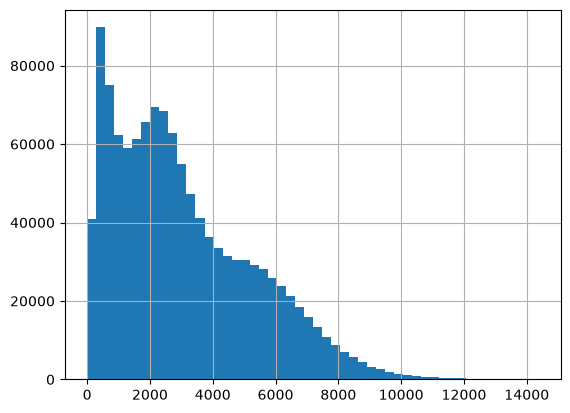

In [85]:
obs['n_genes_by_counts'].hist(bins=50)

check column types and missing values in obs before using any column.

In [86]:
obs.info()

<class 'pandas.DataFrame'>
Index: 1185861 entries, TCAGGTATCCGACATA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0 to GAGATGGCAAGAGAGA-1-scrnacdb9997594__37295__cellranger720_count_37295_scrnacdb9997594_GRCh38-3_0_0
Data columns (total 7 columns):
 #   Column                                  Non-Null Count    Dtype   
---  ------                                  --------------    -----   
 0   sanger_sample_id                        1185861 non-null  category
 1   pct_counts_gene_group__mito_transcript  1185861 non-null  float32 
 2   n_genes_by_counts                       1185861 non-null  int32   
 3   total_counts                            1185861 non-null  float32 
 4   label                                   1185861 non-null  category
 5   category                                1185861 non-null  category
 6   conf_score                              1185861 non-null  category
dtypes: category(4), float32(2), int32(1)
memory usage: 72.9+ MB


In [87]:
obs.describe()

,pct_counts_gene_group__mito_transcript,n_genes_by_counts,total_counts
count,1.185861e+06,1.185861e+06,1.185861e+06
mean,1.289395e+01,3.074326e+03,1.448019e+04
std,1.332018e+01,2.209982e+03,1.970805e+04
min,0.000000e+00,4.000000e+00,1.400000e+01
25%,3.673958e+00,1.290000e+03,2.785000e+03
50%,8.296428e+00,2.593000e+03,7.051000e+03
75%,1.818182e+01,4.508000e+03,2.015400e+04
max,7.999464e+01,1.436400e+04,9.220330e+05


In [88]:
var.head()

,gene_symbols,feature_types,gene_group__mito_transcript,gene_group__mito_protein,gene_group__ribo_protein,gene_group__ribo_rna,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts
ENSG00000243485,MIR1302-2HG,Gene Expression,False,False,False,False,45,1.556939e-05,1.556927e-05,99.998443,45.0,3.828641
ENSG00000237613,FAM138A,Gene Expression,False,False,False,False,2,6.919731e-07,6.919728e-07,99.999931,2.0,1.098612
ENSG00000186092,OR4F5,Gene Expression,False,False,False,False,2,6.919731e-07,6.919728e-07,99.999931,2.0,1.098612
ENSG00000238009,AL627309.1,Gene Expression,False,False,False,False,9340,3.329082e-03,3.323553e-03,99.676849,9622.0,9.171911
ENSG00000239945,AL627309.3,Gene Expression,False,False,False,False,532,1.840648e-04,1.840479e-04,99.981594,532.0,6.278522


confirm every feature is a gene, with no other feature types mixed in.

In [89]:
var['feature_types'].value_counts()

feature_types
Gene Expression    33538
Name: count, dtype: int64

count the genes flagged as mitochondrial; they define the mito % QC metric.

In [90]:
var['gene_group__mito_transcript'].value_counts()

gene_group__mito_transcript
False    33525
True        13
Name: count, dtype: int64

count the ribosomal-protein genes, which we plan to drop before computing gene correlations.

In [91]:
var['gene_group__ribo_protein'].value_counts()

gene_group__ribo_protein
False    33374
True       164
Name: count, dtype: int64

check the ribosomal-RNA flag; if it is False for every gene it carries no information here.

In [92]:
var['gene_group__ribo_rna'].value_counts()

gene_group__ribo_rna
False    33538
Name: count, dtype: int64

In [93]:
var['pct_dropout_by_counts'].describe()

count    33538.000000
mean        94.788122
std          8.736940
min          7.905238
25%         92.570977
50%         99.489774
75%         99.972425
max        100.000000
Name: pct_dropout_by_counts, dtype: float64

Join metadata to obs

before joining, check that the sample IDs in the metadata match those in the expression data, so the join does not silently lose cells.

In [94]:
# check if sample ids in metadata match the sample ids in the expression matrix
mapped_df = pd.read_csv(r"..\data\mapped_data.tsv", sep="\t", index_col=0)
sample_ids_in_metadata = set(mapped_df.index)
sample_ids_in_expression_matrix =  set(obs['sanger_sample_id'])

# Find the intersection of sample IDs
common_sample_ids = sample_ids_in_metadata & sample_ids_in_expression_matrix

# Find the difference of sample IDs
only_in_metadata = sample_ids_in_metadata - sample_ids_in_expression_matrix
only_in_expression_matrix = sample_ids_in_expression_matrix - sample_ids_in_metadata

In [95]:
print(f"Number of sample IDs in metadata: {len(sample_ids_in_metadata)}")
print(f"Number of sample IDs in expression matrix: {len(sample_ids_in_expression_matrix)}")
print(f"Number of common sample IDs: {len(common_sample_ids)}")
print(f"Number of sample IDs only in metadata: {len(only_in_metadata)}")
print(f"Number of sample IDs only in expression matrix: {len(only_in_expression_matrix)}")

Number of sample IDs in metadata: 343
Number of sample IDs in expression matrix: 343
Number of common sample IDs: 343
Number of sample IDs only in metadata: 0
Number of sample IDs only in expression matrix: 0


In [96]:
sample_ids_common = obs['sanger_sample_id'].isin(mapped_df.index).sum()
sample_ids_not_common = (~obs['sanger_sample_id'].isin(mapped_df.index)).sum()
print(sample_ids_common, sample_ids_not_common)

1185861 0


In [97]:
mapped_df.head()

,biopsy_type,bead_version,bead_lot,chip_version,chip_lot,enzyme_lot_BLP,gem_lot,f2_f1_ratio,individual_id,disease_status,age_binned_10,sex,ti_ses_inflamed,health_category
sanger_sample_id,,,,,,,,,,,,,,
5892STDY10205765,terminal ileum,V3.1,NaN,chip-g,lot_160047,SLCB6672,lot_155287,4:1,IBDverse-1-3A5C2FF82FA8A4,CD,40.0,male,inflamed,CD inflamed
5892STDY10315937,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,1:0,IBDverse-1-0DD5B680D0BFFB,CD,60.0,male,inflamed,CD inflamed
5892STDY10315938,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,1:0,IBDverse-1-B257F708E64F29,CD,30.0,female,inflamed,CD inflamed
5892STDY10653007,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,4:1,IBDverse-1-8D29C5BD7C12C7,CD,40.0,female,inflamed,CD inflamed
5892STDY10653009,terminal ileum,V3.1,lot_160848,chip-g,lot_160673,SLCD4967,lot_160851,1:0,IBDverse-1-B45A577AF0E969,CD,30.0,female,inflamed,CD inflamed


In [98]:
obs.head()

,sanger_sample_id,pct_counts_gene_group__mito_transcript,n_genes_by_counts,total_counts,label,category,conf_score
TCAGGTATCCGACATA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.886711,4250,141196.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9987180652351288
CCAATTTAGATACCAA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.929196,4671,108158.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9972390415425336
CATGAGTCAGGCATTT-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.686976,4169,107864.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9770095240845306
TCTCACGGTATCTCGA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.361118,2867,81137.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.772354776734459
TGCGGCAGTCCCAAAT-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.717362,2527,79876.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.98518622462155


sanity check that every cell ID appears once, so each row of obs means exactly one cell.

In [99]:
# check if the index of obs is unique
obs.index.nunique() == obs.shape[0]

True

Join the 2 tables on sanger sample id

In [100]:
obs = obs.join(mapped_df, on='sanger_sample_id', how='left')

confirm the join did not change the number of cells.

In [101]:
obs.shape

(1185861, 21)

In [102]:
obs.describe()

,pct_counts_gene_group__mito_transcript,n_genes_by_counts,total_counts,age_binned_10
count,1.185861e+06,1.185861e+06,1.185861e+06,1.180011e+06
mean,1.289395e+01,3.074326e+03,1.448019e+04,4.498696e+01
std,1.332018e+01,2.209982e+03,1.970805e+04,1.341215e+01
min,0.000000e+00,4.000000e+00,1.400000e+01,2.000000e+01
25%,3.673958e+00,1.290000e+03,2.785000e+03,4.000000e+01
50%,8.296428e+00,2.593000e+03,7.051000e+03,4.000000e+01
75%,1.818182e+01,4.508000e+03,2.015400e+04,6.000000e+01
max,7.999464e+01,1.436400e+04,9.220330e+05,7.000000e+01


Confirm the column types after the join and see how many values are non-null in each column.

In [103]:
obs.info()

<class 'pandas.DataFrame'>
Index: 1185861 entries, TCAGGTATCCGACATA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0 to GAGATGGCAAGAGAGA-1-scrnacdb9997594__37295__cellranger720_count_37295_scrnacdb9997594_GRCh38-3_0_0
Data columns (total 21 columns):
 #   Column                                  Non-Null Count    Dtype   
---  ------                                  --------------    -----   
 0   sanger_sample_id                        1185861 non-null  str     
 1   pct_counts_gene_group__mito_transcript  1185861 non-null  float32 
 2   n_genes_by_counts                       1185861 non-null  int32   
 3   total_counts                            1185861 non-null  float32 
 4   label                                   1185861 non-null  category
 5   category                                1185861 non-null  category
 6   conf_score                              1185861 non-null  category
 7   biopsy_type                             1185861 non-null  str     
 

Count missing values per column to find which cells lack metadata.

In [104]:
obs.isna().sum()

sanger_sample_id                               0
pct_counts_gene_group__mito_transcript         0
n_genes_by_counts                              0
total_counts                                   0
label                                          0
category                                       0
conf_score                                     0
biopsy_type                                    0
bead_version                               13906
bead_lot                                   36603
chip_version                               18748
chip_lot                                   38950
enzyme_lot_BLP                             12864
gem_lot                                    21278
f2_f1_ratio                               908020
individual_id                               5850
disease_status                              5850
age_binned_10                               5850
sex                                         5850
ti_ses_inflamed                             5850
health_category     

Isolate the cells with no donor information so we can see what they are.

In [105]:
# rows with no induvidual information
no_individual_info = obs[obs['individual_id'].isnull()]
print(f"Number of rows with no individual information: {no_individual_info.shape[0]}")
no_individual_info.head()

Number of rows with no individual information: 5850


,sanger_sample_id,pct_counts_gene_group__mito_transcript,n_genes_by_counts,total_counts,label,category,conf_score,biopsy_type,bead_version,bead_lot,...,chip_lot,enzyme_lot_BLP,gem_lot,f2_f1_ratio,individual_id,disease_status,age_binned_10,sex,ti_ses_inflamed,health_category
GCAGTTACAACTACGT-1-5892STDY8357646__32143__cellranger720_count_32143_5892STDY8357646_GRCh38-3_0_0,5892STDY8357646,16.944153,13947,746464.0,Enterocytes precursor crypt KRT20+,Enterocyte,0.5719429835291151,terminal ileum,V3,lot_154306,...,lot_153745,SLBZ4589,lot_154140,1:0,NaN,NaN,NaN,NaN,NaN,NaN
GTCCTCAGTTCTGACA-1-5892STDY8357646__32143__cellranger720_count_32143_5892STDY8357646_GRCh38-3_0_0,5892STDY8357646,13.207969,11945,586661.0,Enterocytes precursor crypt KRT20+,Enterocyte,0.9317621641200352,terminal ileum,V3,lot_154306,...,lot_153745,SLBZ4589,lot_154140,1:0,NaN,NaN,NaN,NaN,NaN,NaN
GACTGATAGTGCTACT-1-5892STDY8357646__32143__cellranger720_count_32143_5892STDY8357646_GRCh38-3_0_0,5892STDY8357646,11.196731,12443,583072.0,Enterocytes precursor crypt KRT20+,Enterocyte,0.999254100432725,terminal ileum,V3,lot_154306,...,lot_153745,SLBZ4589,lot_154140,1:0,NaN,NaN,NaN,NaN,NaN,NaN
CTCGAGGCACTGTGTA-1-5892STDY8357646__32143__cellranger720_count_32143_5892STDY8357646_GRCh38-3_0_0,5892STDY8357646,18.605526,12746,491655.0,Enterocytes precursor crypt KRT20+,Enterocyte,0.9946284444597993,terminal ileum,V3,lot_154306,...,lot_153745,SLBZ4589,lot_154140,1:0,NaN,NaN,NaN,NaN,NaN,NaN
CAGCAATTCGCCTTTG-1-5892STDY8357646__32143__cellranger720_count_32143_5892STDY8357646_GRCh38-3_0_0,5892STDY8357646,11.755560,12888,373653.0,Enterocytes progenitor crypt OLFM4-hi,Enterocyte,0.9607802376440736,terminal ileum,V3,lot_154306,...,lot_153745,SLBZ4589,lot_154140,1:0,NaN,NaN,NaN,NaN,NaN,NaN


Find which sample these cells come from.

In [106]:
no_individual_info['sanger_sample_id'].value_counts()

sanger_sample_id
5892STDY8357646    5850
Name: count, dtype: int64

In [107]:
print('unique samples:', obs['sanger_sample_id'].nunique())
print('unique individuals:', obs['individual_id'].nunique())

unique samples: 343
unique individuals: 342


Let us drop the rows with donor data - 5850. remove the cells with no donor information, because we cannot assign them to a health group.

In [108]:
obs = obs.dropna(subset=['individual_id'])
obs['individual_id'].isnull().sum()

np.int64(0)

In [109]:
obs['health_category'].value_counts()

health_category
Healthy          619805
CD inflamed      307880
CD uninflamed    252326
Name: count, dtype: int64

See the cell-type makeup within each health group

In [110]:
obs.groupby('category')['health_category'].value_counts()

category       health_category
B cell         Healthy             89318
               CD inflamed         28345
               CD uninflamed       23586
Enterocyte     Healthy            167255
               CD uninflamed       57741
               CD inflamed         51213
Mesenchymal    Healthy              5293
               CD uninflamed        3089
               CD inflamed          2851
Myeloid        CD inflamed         40377
               Healthy             29637
               CD uninflamed       17166
Plasma B cell  CD inflamed         56214
               Healthy             40674
               CD uninflamed       28858
Secretory      Healthy             98197
               CD uninflamed       36497
               CD inflamed         28630
Stem cell      Healthy             47405
               CD uninflamed       17179
               CD inflamed         15121
T cell         Healthy            142026
               CD inflamed         85129
               CD uninflam

Sanity check that every donor belongs to exactly one health category.

In [111]:
obs.groupby('individual_id')['health_category'].nunique().sum() == obs['individual_id'].nunique()

np.True_

Check cell statistics

In [112]:
obs.groupby('health_category')['individual_id'].nunique()

health_category
CD inflamed       63
CD uninflamed     47
Healthy          232
Name: individual_id, dtype: int64

In [113]:
obs['individual_id'].value_counts().aggregate(['mean', 'median', 'min', 'max'])

mean       3450.324561
median     2890.500000
min         311.000000
max       12848.000000
Name: count, dtype: float64

In [114]:
# cells per donor
cells_per_donor = obs.groupby('individual_id').size()
cells_per_donor.describe()

count      342.000000
mean      3450.324561
std       2166.041434
min        311.000000
25%       1943.750000
50%       2890.500000
75%       4436.000000
max      12848.000000
dtype: float64

Look at the shape of the cells-per-donor distribution on a log scale, with the median marked.

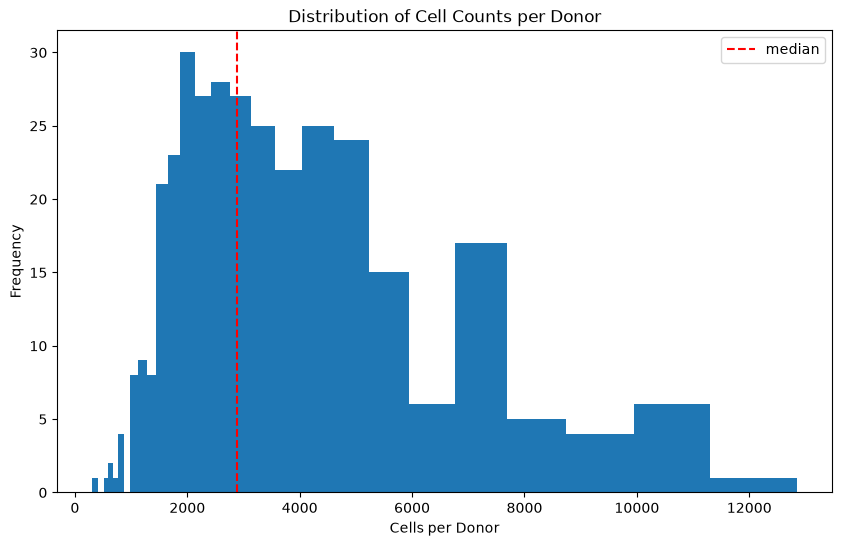

In [115]:
# histogram plot of cells per donor
plt.figure(figsize=(10, 6))
plt.hist(cells_per_donor, bins=np.logspace(np.log10(cells_per_donor.min()),np.log10(cells_per_donor.max()), 30))
plt.axvline(cells_per_donor.median(), color='red', ls='--', label='median')
plt.legend()
plt.xlabel('Cells per Donor')
plt.ylabel('Frequency')
plt.title('Distribution of Cell Counts per Donor')
plt.show()

Compare linear and log scales to show why the log scale is easier to read for skewed counts.

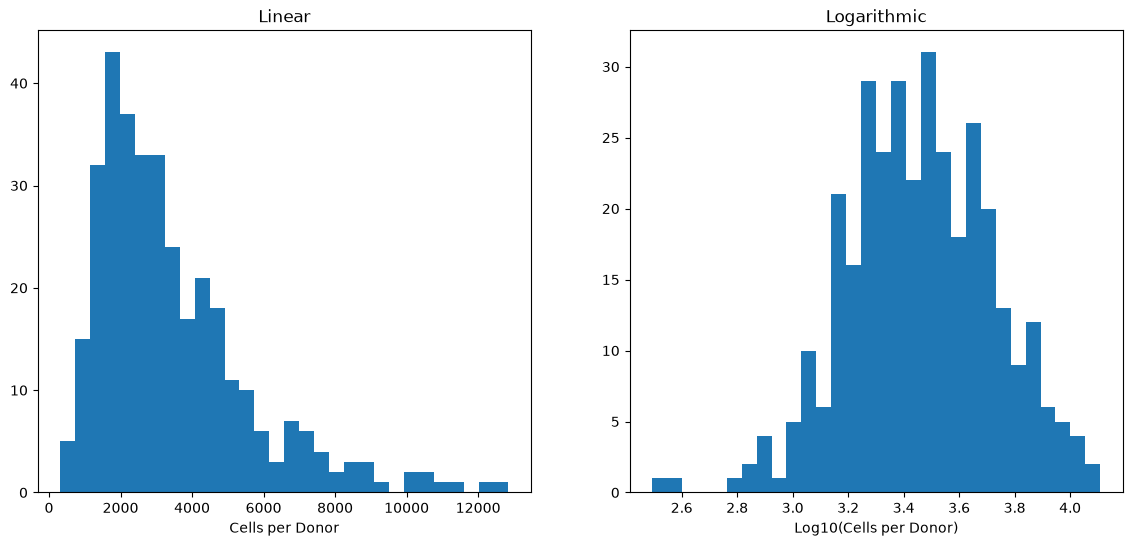

In [116]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].hist(cells_per_donor, bins=30)
ax[0].set_title('Linear')
ax[1].hist(np.log10(cells_per_donor), bins=30)
ax[1].set_title('Logarithmic')
ax[0].set_xlabel('Cells per Donor')
ax[1].set_xlabel('Log10(Cells per Donor)')
plt.show()

cell-type table of cell counts (plus a total column)

In [117]:
cells_per_donor_celltypes = obs.groupby(['individual_id', 'category', 'health_category']).size().unstack('category', fill_value=0)
cells_per_donor_celltypes['total'] = cells_per_donor_celltypes.sum(axis=1)
cells_per_donor_celltypes.head()

,category,B cell,Enterocyte,Mesenchymal,Myeloid,Plasma B cell,Secretory,Stem cell,T cell,total
individual_id,health_category,,,,,,,,,
IBDverse-1-0045EBB9CBFB5F,Healthy,1384,74,7,160,171,149,27,606,2578
IBDverse-1-007DB71942EA7A,CD inflamed,710,701,10,292,967,602,94,1045,4421
IBDverse-1-0150BDB36ABEBC,Healthy,1,163,28,68,66,125,121,178,750
IBDverse-1-01C1EA8FD8CD67,Healthy,280,691,8,48,107,600,251,329,2314
IBDverse-1-0244A66A937BB2,Healthy,681,384,6,89,113,220,214,404,2111


In [118]:
# how many donors per group, and cells per donor
cells_per_donor_celltypes.groupby('health_category')['total'].describe()

,count,mean,std,min,25%,50%,75%,max
health_category,,,,,,,,
CD inflamed,63.0,4886.984127,2087.305050,836.0,3780.50,4636.0,5834.00,12848.0
CD uninflamed,47.0,5368.638298,2544.914720,1737.0,3554.00,4707.0,6825.00,12371.0
Healthy,232.0,2671.573276,1595.650412,311.0,1692.75,2304.0,3226.25,11252.0


Compare cells per donor across cell types on a log scale to see which types are abundant and which are sparse.

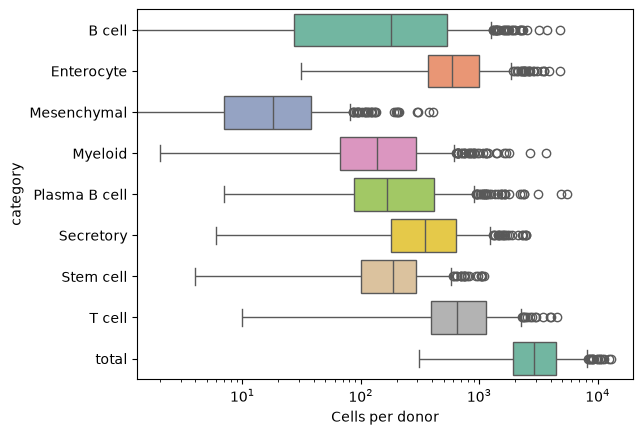

In [119]:
# boxplot of cells per donor by health category
sns.boxplot(data=cells_per_donor_celltypes, orient='h', palette='Set2')
plt.xlabel('Cells per donor')
plt.xscale('log')
plt.show()

Convert counts to fractions of each donor's cells, so donors with different total cell numbers become comparable.

Text(0, 0.5, 'Cell Type')

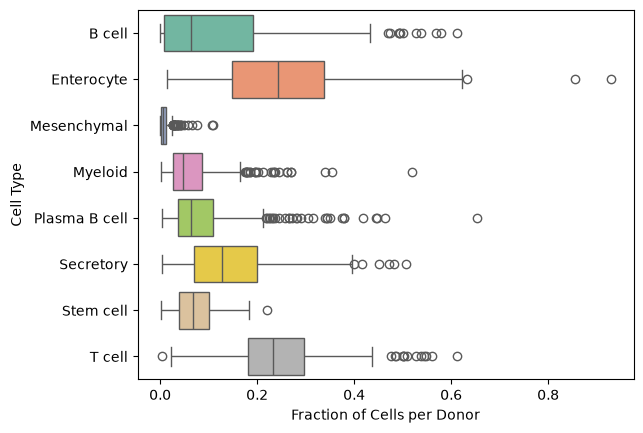

In [120]:
fractions = cells_per_donor_celltypes.div(cells_per_donor_celltypes['total'], axis=0).reset_index()
fractions.drop(columns='total', inplace=True)
sns.boxplot(data=fractions, orient='h', palette='Set2')
plt.xlabel('Fraction of Cells per Donor')
plt.ylabel('Cell Type')

Why: check whether total cells per donor differs by health group, since that would distort raw-count comparisons.

<Axes: xlabel='health_category', ylabel='total'>

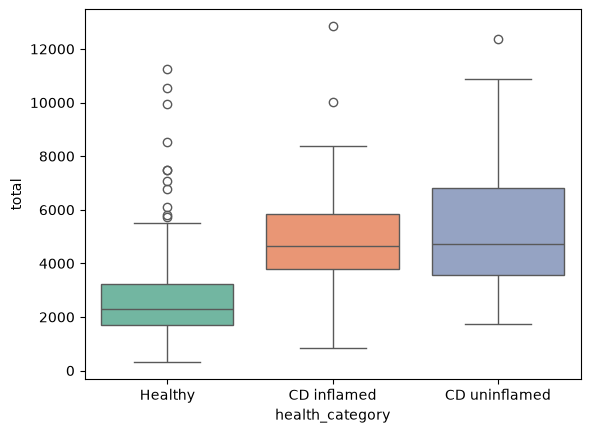

In [121]:
# total cells per donor by health category
sns.boxplot(data=cells_per_donor_celltypes, x='health_category', y='total', hue='health_category', palette='Set2')

Reshape the fractions table from wide to long format, which seaborn needs for grouped plots.

In [122]:
fraction_df = fractions.melt(id_vars=['health_category', 'individual_id'], var_name='category', value_name='fraction')
fraction_df['category'].value_counts()

category
B cell           342
Enterocyte       342
Mesenchymal      342
Myeloid          342
Plasma B cell    342
Secretory        342
Stem cell        342
T cell           342
Name: count, dtype: int64

Compare each cell type's fraction between health groups - does the cell mix change with disease?

<Axes: xlabel='category', ylabel='fraction'>

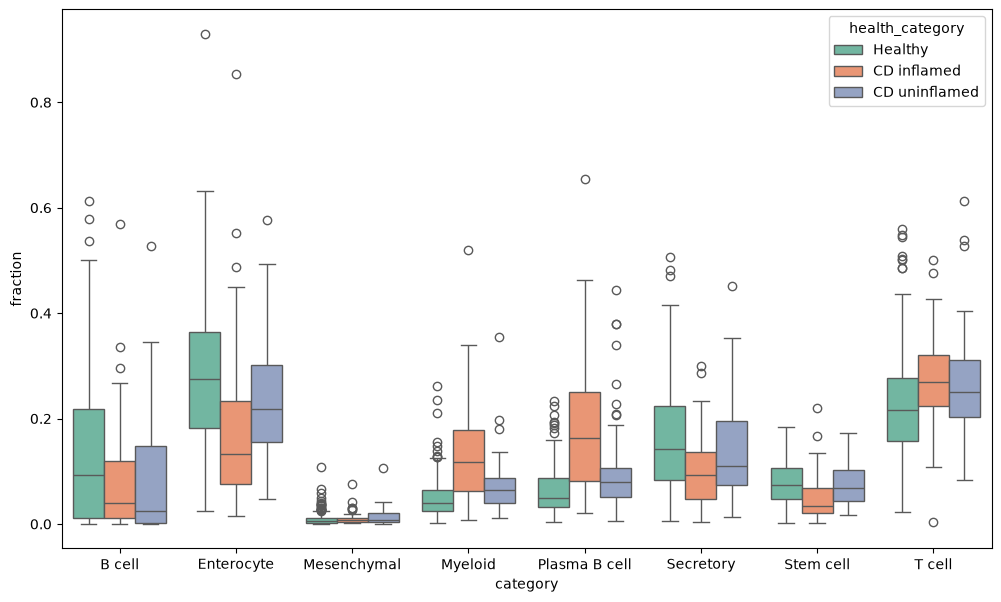

In [123]:
plt.figure(figsize=(12, 7))
sns.boxplot(data=fraction_df, x='category', y='fraction', hue='health_category', palette='Set2')

look at whether the lab's f2_f1 ratio lines up with health group

<Axes: xlabel='f2_f1_ratio', ylabel='n_cells'>

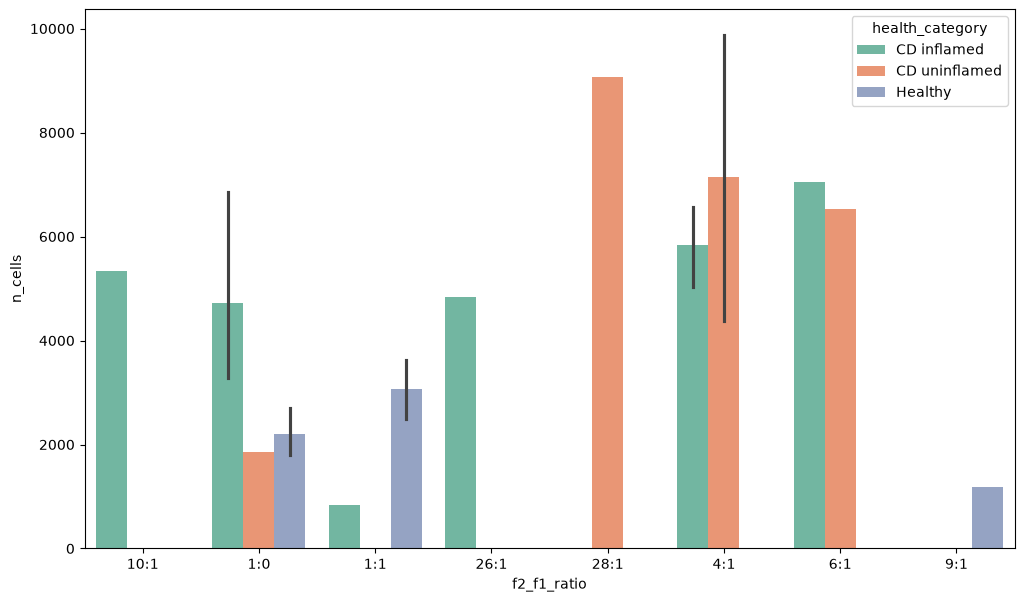

In [124]:
f2_f1 = obs.groupby(['f2_f1_ratio', 'health_category', 'individual_id']).size().reset_index(name='n_cells')
plt.figure(figsize=(12, 7))
sns.barplot(data=f2_f1, x='f2_f1_ratio', y='n_cells', hue='health_category', palette='Set2')

conf_score is stored as text (category), so convert it to float before filtering or plotting it.

In [125]:
obs['conf_score'] = obs['conf_score'].astype(float)
obs['conf_score'].describe()

count    1.180011e+06
mean     9.679599e-01
std      7.907350e-02
min      5.000073e-01
25%      9.832037e-01
50%      9.984712e-01
75%      9.999103e-01
max      1.000000e+00
Name: conf_score, dtype: float64

count cells whose cell-type label has confidence below 0.5, to decide whether low-confidence labels need removing.

In [126]:
(obs['conf_score']<0.5).sum()

np.int64(0)

In [127]:
cells_per_donor_celltypes.head()

,category,B cell,Enterocyte,Mesenchymal,Myeloid,Plasma B cell,Secretory,Stem cell,T cell,total
individual_id,health_category,,,,,,,,,
IBDverse-1-0045EBB9CBFB5F,Healthy,1384,74,7,160,171,149,27,606,2578
IBDverse-1-007DB71942EA7A,CD inflamed,710,701,10,292,967,602,94,1045,4421
IBDverse-1-0150BDB36ABEBC,Healthy,1,163,28,68,66,125,121,178,750
IBDverse-1-01C1EA8FD8CD67,Healthy,280,691,8,48,107,600,251,329,2314
IBDverse-1-0244A66A937BB2,Healthy,681,384,6,89,113,220,214,404,2111


In [128]:
# donors per group per cell type
cells_per_donor_celltypes.drop(columns='total', inplace=True)

category         B cell  Enterocyte  Mesenchymal  Myeloid  Plasma B cell  \
health_category                                                            
CD inflamed          56          63           42       63             63   
CD uninflamed        34          47           33       47             47   
Healthy             173         232           86      221            220   

category         Secretory  Stem cell  T cell  
health_category                                
CD inflamed             63         59      62  
CD uninflamed           47         47      47  
Healthy                228        228     231  


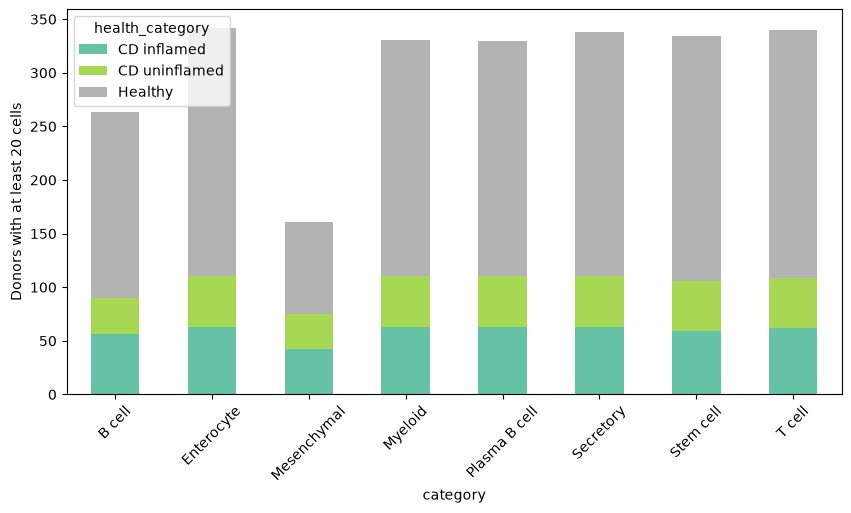

In [129]:
donor_per_type = (cells_per_donor_celltypes >= 20).groupby('health_category').sum()
print(donor_per_type)

donor_per_type.T.plot(kind='bar', figsize=(10, 5), colormap='Set2', rot=45, stacked=True)
plt.ylabel(f'Donors with at least {20} cells')
plt.show()


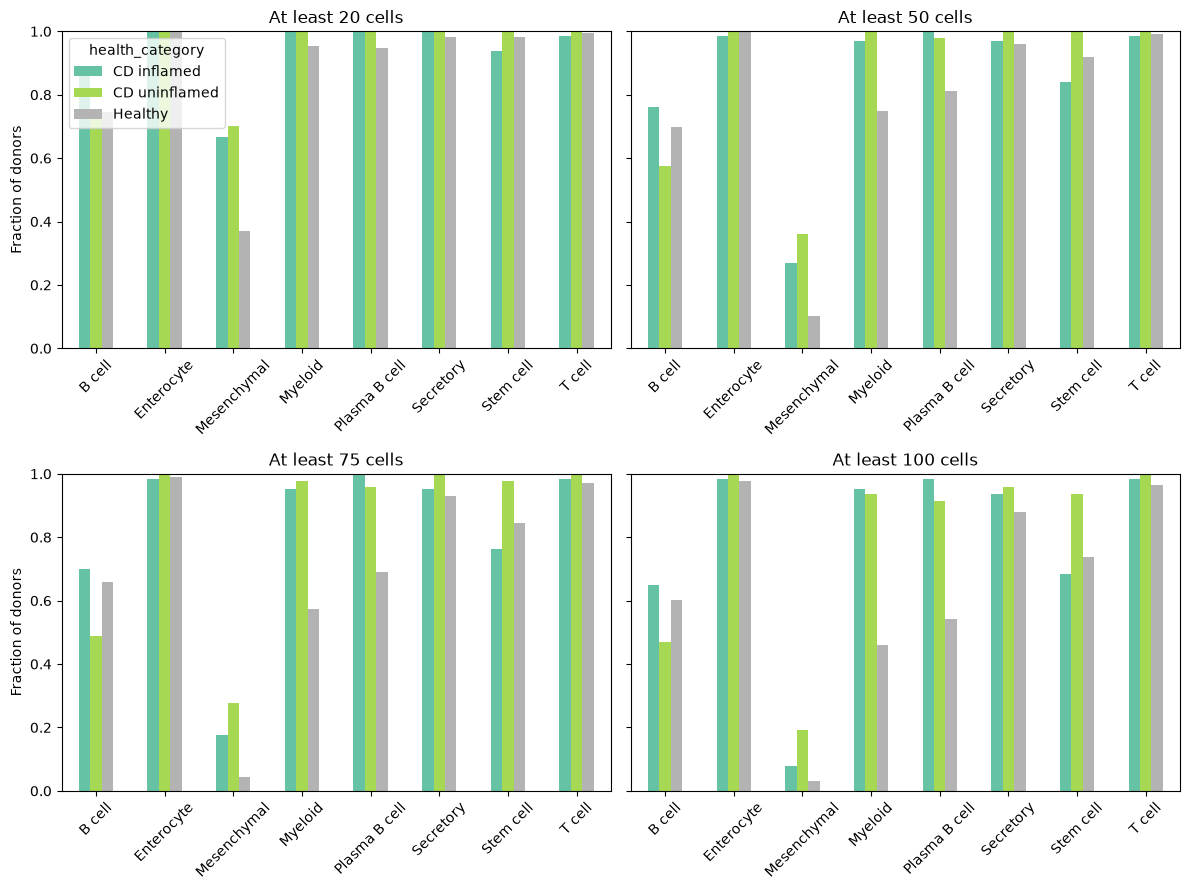

In [130]:
min_cells = [20, 50, 75, 100]
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)

for ax, n in zip(axes.flat, min_cells):
    frac = (cells_per_donor_celltypes >= n).groupby('health_category').mean()
    frac.T.plot(kind='bar', ax=ax, colormap='Set2', rot=45, legend=(ax is axes[0, 0]), )
    ax.set_title(f'At least {n} cells')
    ax.set_ylim(0, 1)
    ax.set_xlabel('')

axes[0, 0].set_ylabel('Fraction of donors')
axes[1, 0].set_ylabel('Fraction of donors')
fig.tight_layout()
plt.show()
